Question 1

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces


In [3]:
roll_number = "M26CSE005"

In [4]:
seed = int("".join([ch for ch in roll_number if ch.isdigit()]))

In [5]:
seed


26005

In [6]:
rng = np.random.default_rng(seed)
print("Using seed: ",seed)

Using seed:  26005


In [7]:
faces = fetch_olivetti_faces()
x = faces.data
y = faces.target

In [8]:
train_idx,val_idx,test_idx = [],[],[]
for person_id in range(40):
    person_indices = np.where(y == person_id)[0]
    shuffled=rng.permutation(person_indices)
    train_idx.extend(shuffled[:6])
    val_idx.extend(shuffled[6:8])
    test_idx.extend(shuffled[8:10])
train_idx = np.array(train_idx) 
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

x_train,y_train = x[train_idx],y[train_idx]
x_val,y_val = x[val_idx],y[val_idx]
x_test,y_test = x[test_idx],y[test_idx]

In [9]:
temp_images = x_test.copy().reshape(-1,64,64)
temp_images[:,24:40,24:40] = 0.0
x_test_masked = temp_images.reshape(-1,4096)
np.savez(
    "olivetti_splits.npz",
    train_idx = train_idx,val_idx = val_idx,test_idx =test_idx,
    x_train = x_train, y_train = y_train,
    x_val = x_val, y_val = y_val,
    x_test = x_test , y_test = y_test,
    x_test_masked = x_test_masked
)

In [10]:
assert x_train.shape == (240, 4096), f"Expected (240, 4096), got {x_train.shape}"
assert x_val.shape   == (80, 4096),  f"Expected (80, 4096), got {x_val.shape}"
assert x_test.shape  == (80, 4096),  f"Expected (80, 4096), got {x_test.shape}"

# 2. Check no data leakage (no overlapping indices between splits)
assert len( np.intersect1d(train_idx, val_idx) ) == 0, "Leakage between train and val!"
assert len( np.intersect1d(train_idx, test_idx) ) == 0, "Leakage between train and test!"
assert len( np.intersect1d(val_idx, test_idx) ) == 0, "Leakage between val and test!"

# 3. Check exact class balance (6 per class in train, 2 in val, 2 in test)
assert np.all(np.bincount(y_train) == 6), "Train does not have 6 per identity!"
assert np.all(np.bincount(y_val)   == 2), "Val does not have 2 per identity!"
assert np.all(np.bincount(y_test)  == 2), "Test does not have 2 per identity!"

# 4. Check that the mask zeroed out exactly 16x16 = 256 pixels and didn't modify X_test
diff_pixels = np.sum(x_test[0] != x_test_masked[0])
assert diff_pixels <= 256 and np.all(x_test_masked.reshape(-1, 64, 64)[:, 24:40, 24:40] == 0), "Masking error!"
print("All Step 1 checks passed!")

All Step 1 checks passed!


In [11]:
print("Number of changed pixels in image 0:", np.sum(x_test[0] != x_test_masked[0]))
print("Max value inside [24:40, 24:40] of masked:", np.max(x_test_masked.reshape(-1, 64, 64)[:, 24:40, 24:40]))
print("Max value inside [24:40, 24:40] of clean x_test:", np.max(x_test.reshape(-1, 64, 64)[:, 24:40, 24:40]))

Number of changed pixels in image 0: 256
Max value inside [24:40, 24:40] of masked: 0.0
Max value inside [24:40, 24:40] of clean x_test: 0.9214876


In [12]:
#1(A)
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

depths = [2,4,8,16, None]
min_leaves = [1,2,4]
results_q1a =[]

for d in depths:
    for m in min_leaves:
        clf = DecisionTreeClassifier(max_depth=d,min_samples_leaf=m,random_state=seed)
        clf.fit(x_train,y_train)

        tr_acc = clf.score(x_train,y_train)
        val_acc = clf.score(x_val,y_val)
        te_acc = clf .score(x_test,y_test)

        n_leaves = clf.get_n_leaves()
        leaf_ids = clf.apply(x_train)
        unique_leaves,leaf_counts = np.unique(leaf_ids,return_counts = True)

        mean_samples = np.mean(leaf_counts)
        frac_single = np.mean(leaf_counts == 1)

        results_q1a.append({
            "max_depth" : str(d),
            "min_samples_leaf": m,
            "train_acc": round(tr_acc,4),
            "val_acc": round(val_acc,4),
            "test_acc": round(te_acc,4),
            "n_leaves": n_leaves,
            "mean_samples_leaf": round(mean_samples,2),
            "frac_single_leaf": round(frac_single,4)
        })

        df_q1a = pd.DataFrame(results_q1a)
        print(df_q1a.to_string(index = False))

max_depth  min_samples_leaf  train_acc  val_acc  test_acc  n_leaves  mean_samples_leaf  frac_single_leaf
        2                 1      0.075   0.0625      0.05         3               80.0               0.0
max_depth  min_samples_leaf  train_acc  val_acc  test_acc  n_leaves  mean_samples_leaf  frac_single_leaf
        2                 1      0.075   0.0625      0.05         3               80.0               0.0
        2                 2      0.075   0.0625      0.05         3               80.0               0.0
max_depth  min_samples_leaf  train_acc  val_acc  test_acc  n_leaves  mean_samples_leaf  frac_single_leaf
        2                 1      0.075   0.0625      0.05         3               80.0               0.0
        2                 2      0.075   0.0625      0.05         3               80.0               0.0
        2                 4      0.075   0.0625      0.05         3               80.0               0.0
max_depth  min_samples_leaf  train_acc  val_acc  test_a

Theoretical Distinct (Exact):151.89 | (1-1/e):151.71

  B  train_acc  val_acc  test_acc  avg_distinct  oob_acc  disagreement  vote_margin
  1     0.7042   0.3125    0.4125        149.00   0.2198        0.0000       1.0000
  5     0.9750   0.5625    0.6000        151.80   0.3364        0.7650       0.2625
 10     0.9917   0.7000    0.8000        150.70   0.4160        0.7517       0.2775
 25     1.0000   0.8000    0.8375        152.04   0.5958        0.7536       0.2975
 50     1.0000   0.8750    0.8375        152.42   0.7208        0.7616       0.3022
100     1.0000   0.8875    0.8625        152.38   0.7458        0.7652       0.3074
200     1.0000   0.9000    0.8875        152.72   0.8125        0.7654       0.3086


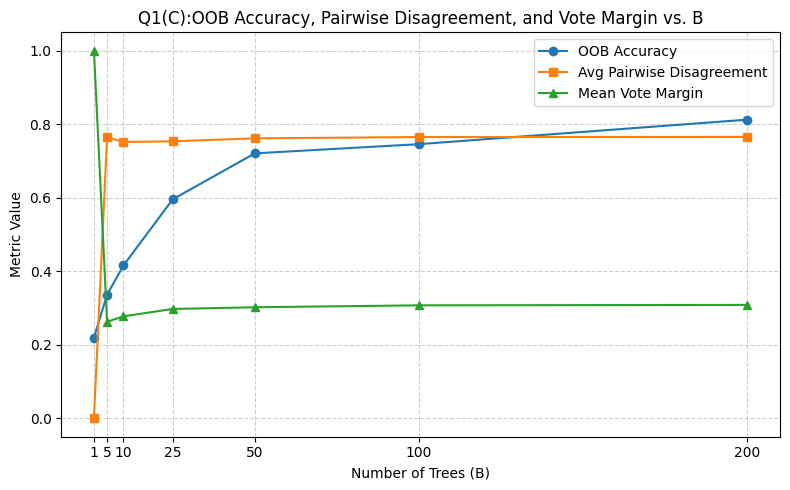

In [13]:
#Q1(B) and Q1(C)
FROZEN_DEPTH = None
FROZEN_MIN_LEAF = 1

B_values = [1,5,10,25,50,100,200]
N_train = x_train.shape[0]
K=40

theoretical_distinct_exact = N_train * (1-(1-1/N_train)** N_train)
theoretical_distinct_asymp = N_train *(1-np.exp(-1))
print(f"Theoretical Distinct (Exact):{theoretical_distinct_exact:.2f} | (1-1/e):{theoretical_distinct_asymp:.2f}\n")

def majority_vote_and_margin(tree_preds_matrix,num_classes =40):
    B,n_samples = tree_preds_matrix.shape
    vote_counts = np.zeros((n_samples,num_classes),dtype = np.float64)
    for b in range(B):
        vote_counts[np.arange(n_samples),tree_preds_matrix[b]] += 1.0
    vote_fractions = vote_counts/B
    final_preds = np.argmax(vote_fractions,axis=1)
    sorted_fracs = np.sort(vote_fractions,axis=1)
    margins = sorted_fracs[:,-1] - sorted_fracs[:,-2]
    mean_margin = np.mean(margins)
    return final_preds,mean_margin,vote_fractions

results_q1bc = []
trained_bagging_models = {}
for B in B_values:
    rng_bag = np.random.default_rng(seed)
    trees = []
    distinct_counts = []
    oob_votes = np.zeros((N_train,K),dtype=np.float64)
    for b in range(B):
        boot_idx = rng_bag.choice(N_train,size=N_train,replace=True)
        distinct_counts.append(len(np.unique(boot_idx)))

        tree_seed = int(rng_bag.integers(0,2**31-1))
        tree = DecisionTreeClassifier(
            max_depth = FROZEN_DEPTH,
            min_samples_leaf = FROZEN_MIN_LEAF,
            random_state = tree_seed
        )
        tree.fit(x_train[boot_idx],y_train[boot_idx])
        trees.append(tree)

        oob_idx = np.setdiff1d(np.arange(N_train),boot_idx)
        oob_preds = tree.predict(x_train[oob_idx])
        oob_votes[oob_idx,oob_preds] += 1.0

    trained_bagging_models[B]=trees

    train_tree_preds = np.array([t.predict(x_train) for t in trees])
    val_tree_preds = np.array([t.predict(x_val) for t in trees])
    test_tree_preds = np.array([t.predict(x_test) for t in trees])

    train_ens_pred, _, _ =majority_vote_and_margin(train_tree_preds,K)
    val_ens_pred,val_margin, _ = majority_vote_and_margin(val_tree_preds,K)
    test_ens_pred, _, _ = majority_vote_and_margin(test_tree_preds,K)

    has_oob = np.sum(oob_votes,axis=1)>0
    oob_acc = np.mean(np.argmax(oob_votes[has_oob],axis=1) == y_train[has_oob])

    if B == 1:
        avg_disagreement =0.0
    else:
        pair_disagreements = []
        for i in range(B):
            for j in range(i+1,B):
                pair_disagreements.append(np.mean(val_tree_preds[i] != val_tree_preds[j]))
        avg_disagreement = np.mean(pair_disagreements)
    results_q1bc.append({
        "B":B,
        "train_acc": round(np.mean(train_ens_pred == y_train),4),
        "val_acc":round(np.mean(val_ens_pred == y_val),4),
        "test_acc":round(np.mean(test_ens_pred == y_test),4),
        "avg_distinct": round(np.mean(distinct_counts),2),
        "oob_acc": round(oob_acc,4),
        "disagreement": round(avg_disagreement,4),
        "vote_margin":round(val_margin,4)
    })    

df_q1bc = pd.DataFrame(results_q1bc)
print(df_q1bc.to_string(index=False))

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(df_q1bc["B"],df_q1bc["oob_acc"],marker='o',label = "OOB Accuracy")
plt.plot(df_q1bc["B"],df_q1bc["disagreement"],marker='s',label ="Avg Pairwise Disagreement")
plt.plot(df_q1bc["B"],df_q1bc["vote_margin"],marker='^',label="Mean Vote Margin")
plt.xlabel("Number of Trees (B)")
plt.ylabel("Metric Value")
plt.title("Q1(C):OOB Accuracy, Pairwise Disagreement, and Vote Margin vs. B")
plt.xticks(B_values)
plt.grid(True,linestyle="--",alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

=== Q1(d): Clean vs Masked Test Set Comparison ===
                Model  Clean Test Acc  Clean Mean Conf  Masked Test Acc  Masked Mean Conf
   Frozen Single Tree          0.4625           1.0000           0.4625            1.0000
Final Bagging (B=200)          0.8875           0.3957           0.8000            0.2918

--- Two Faces Where Bagging Corrects Single Tree (Clean Test) ---
Test Sample #2 | True Class: 1 | Single Tree Pred: 15 | Bagging Pred: 1
   Bagging Top-3 Votes -> Class 1: 116/200 votes, Class 6: 11/200 votes, Class 33: 7/200 votes (True Class 1 got 116/200 votes)
Test Sample #4 | True Class: 2 | Single Tree Pred: 3 | Bagging Pred: 2
   Bagging Top-3 Votes -> Class 2: 47/200 votes, Class 3: 15/200 votes, Class 37: 10/200 votes (True Class 2 got 47/200 votes)

--- Two Faces Where Both Single Tree and Bagging Are Wrong (Clean Test) ---
Test Sample #0 | True Class: 0 | Single Tree Pred: 7 | Bagging Pred: 7
   Bagging Top-3 Votes -> Class 7: 36/200 votes, Class 26: 31/200 

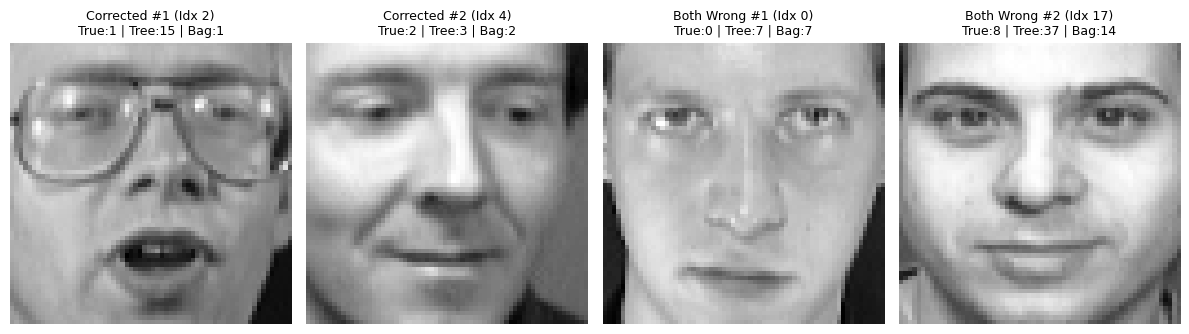

In [14]:
# Q1(d): Frozen Single Tree vs Final Bagged Model (B=200) on Clean & Masked Test Sets 

single_tree = DecisionTreeClassifier(
    max_depth=FROZEN_DEPTH,
    min_samples_leaf=FROZEN_MIN_LEAF,
    random_state=seed
)
single_tree.fit(x_train, y_train)


B_FINAL = 200
final_bag_trees = trained_bagging_models[B_FINAL]

def evaluate_single_tree(clf, X_eval, y_eval):
    preds = clf.predict(X_eval)
    probs = clf.predict_proba(X_eval)
    conf  = np.mean(np.max(probs, axis=1))
    acc   = np.mean(preds == y_eval)
    return preds, acc, conf

def evaluate_bagging(trees, X_eval, y_eval, num_classes=40):
    B = len(trees)
    n_samples = X_eval.shape[0]
    tree_preds = np.array([t.predict(X_eval) for t in trees])
    
    vote_counts = np.zeros((n_samples, num_classes), dtype=int)
    for b in range(B):
        vote_counts[np.arange(n_samples), tree_preds[b]] += 1
        
    preds = np.argmax(vote_counts, axis=1)
    conf  = np.mean(np.max(vote_counts / B, axis=1))
    acc   = np.mean(preds == y_eval)
    return preds, acc, conf, vote_counts


st_clean_preds, st_clean_acc, st_clean_conf = evaluate_single_tree(single_tree, x_test, y_test)
st_mask_preds,  st_mask_acc,  st_mask_conf  = evaluate_single_tree(single_tree, x_test_masked, y_test)

bag_clean_preds, bag_clean_acc, bag_clean_conf, bag_clean_votes = evaluate_bagging(final_bag_trees, x_test, y_test)
bag_mask_preds,  bag_mask_acc,  bag_mask_conf,  bag_mask_votes  = evaluate_bagging(final_bag_trees, x_test_masked, y_test)

df_q1d = pd.DataFrame([
    {
        "Model": "Frozen Single Tree",
        "Clean Test Acc": round(st_clean_acc, 4),
        "Clean Mean Conf": round(st_clean_conf, 4),
        "Masked Test Acc": round(st_mask_acc, 4),
        "Masked Mean Conf": round(st_mask_conf, 4)
    },
    {
        "Model": f"Final Bagging (B={B_FINAL})",
        "Clean Test Acc": round(bag_clean_acc, 4),
        "Clean Mean Conf": round(bag_clean_conf, 4),
        "Masked Test Acc": round(bag_mask_acc, 4),
        "Masked Mean Conf": round(bag_mask_conf, 4)
    }
])
print("=== Q1(d): Clean vs Masked Test Set Comparison ===")
print(df_q1d.to_string(index=False))

# --- 3. Find 2 faces where Bagging corrects the Single Tree, and 2 where BOTH are wrong ---
corrected_idx = np.where((st_clean_preds != y_test) & (bag_clean_preds == y_test))[0][:2]
both_wrong_idx = np.where((st_clean_preds != y_test) & (bag_clean_preds != y_test))[0][:2]

def print_case_details(indices, title):
    print(f"\n--- {title} ---")
    for idx in indices:
        true_id = y_test[idx]
        st_pred = st_clean_preds[idx]
        bag_pred = bag_clean_preds[idx]
        
     
        votes = bag_clean_votes[idx]
        top3_classes = np.argsort(votes)[::-1][:3]
        top3_str = ", ".join([f"Class {c}: {votes[c]}/{B_FINAL} votes" for c in top3_classes])
        true_votes = votes[true_id]
        
        print(f"Test Sample #{idx} | True Class: {true_id} | Single Tree Pred: {st_pred} | Bagging Pred: {bag_pred}")
        print(f"   Bagging Top-3 Votes -> {top3_str} (True Class {true_id} got {true_votes}/{B_FINAL} votes)")

print_case_details(corrected_idx, "Two Faces Where Bagging Corrects Single Tree (Clean Test)")
print_case_details(both_wrong_idx, "Two Faces Where Both Single Tree and Bagging Are Wrong (Clean Test)")


fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
all_four = list(corrected_idx) + list(both_wrong_idx)
titles = ["Corrected #1", "Corrected #2", "Both Wrong #1", "Both Wrong #2"]

for ax, idx, t_label in zip(axes, all_four, titles):
    ax.imshow(x_test[idx].reshape(64, 64), cmap="gray")
    ax.set_title(f"{t_label} (Idx {idx})\nTrue:{y_test[idx]} | Tree:{st_clean_preds[idx]} | Bag:{bag_clean_preds[idx]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Question - 2

In [15]:
# --- Q2(a): 3-Class Toy Example (N = 6 samples, K = 3 classes) & Reusable SAMME Step ---

def samme_single_step(X_data, y_data, w, max_depth, K, tree_seed):
    """
    Runs one complete round of SAMME and returns:
      tree, preds, err, alpha, w_updated, is_valid
    Handles explicitly any weak learner not better than random guessing (err >= 1 - 1/K).
    """
    tree = DecisionTreeClassifier(max_depth=max_depth, random_state=tree_seed)
    tree.fit(X_data, y_data, sample_weight=w)
    preds = tree.predict(X_data)
    
    # Indicator of misclassification: 1.0 if wrong, 0.0 if correct
    incorrect = (preds != y_data).astype(np.float64)
    
    # Weighted error
    err = float(np.dot(w, incorrect) / np.sum(w))
    
    # Random guessing threshold for K classes is (1 - 1/K)
    max_allowed_err = 1.0 - (1.0 / K)
    
    # Handle weak learner not better than random prediction (or perfect 0 error)
    if err >= max_allowed_err - 1e-12:
        return tree, preds, err, 0.0, w.copy(), False
    
    err_clipped = np.clip(err, 1e-12, max_allowed_err - 1e-12)
    
    # SAMME alpha formula: log((1 - err) / err) + log(K - 1)
    alpha = float(np.log((1.0 - err_clipped) / err_clipped) + np.log(K - 1.0))
    
    # Update sample weights: multiply misclassified samples by exp(alpha) and normalise
    w_unnorm = w * np.exp(alpha * incorrect)
    w_updated = w_unnorm / np.sum(w_unnorm)
    
    return tree, preds, err, alpha, w_updated, True

# Create a 3-class toy dataset with 6 samples (2 features)
X_toy = np.array([
    [1.0, 2.0], [1.5, 1.8],  # Class 0
    [5.0, 8.0], [6.0, 9.0],  # Class 1
    [9.0, 1.0], [8.5, 2.0]   # Class 2
])
y_toy = np.array([0, 0, 1, 1, 2, 2])
K_toy = 3
N_toy = len(y_toy)

# Initial uniform sample weights
w_init = np.ones(N_toy, dtype=np.float64) / N_toy

# Run 1 round of SAMME with a depth-1 stump (which can only predict at most 2 of the 3 classes!)
_, toy_preds, toy_err, toy_alpha, w_next, valid = samme_single_step(
    X_toy, y_toy, w_init, max_depth=1, K=K_toy, tree_seed=seed
)

print("=== Q2(a): One Complete SAMME Round on 3-Class Toy Example (N=6, K=3) ===")
print(f"True Labels y        : {y_toy}")
print(f"Initial Weights w^(1): {np.round(w_init, 4)}")
print(f"Weak Learner Preds   : {toy_preds}")
print(f"Misclassified Mask   : {(toy_preds != y_toy).astype(int)}")
print(f"Weighted Error (eps) : {toy_err:.4f}  (Random threshold 1 - 1/K = {1 - 1/K_toy:.4f})")
print(f"Learner Weight (alpha): {toy_alpha:.4f}")
print(f"Updated Weights w^(2): {np.round(w_next, 4)}  (Sum = {np.sum(w_next):.4f})")

=== Q2(a): One Complete SAMME Round on 3-Class Toy Example (N=6, K=3) ===
True Labels y        : [0 0 1 1 2 2]
Initial Weights w^(1): [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]
Weak Learner Preds   : [0 0 1 1 1 1]
Misclassified Mask   : [0 0 0 0 1 1]
Weighted Error (eps) : 0.3333  (Random threshold 1 - 1/K = 0.6667)
Learner Weight (alpha): 1.3863
Updated Weights w^(2): [0.0833 0.0833 0.0833 0.0833 0.3333 0.3333]  (Sum = 1.0000)


Training SAMME models for depths 1, 2, 3, 4 (up to 100 rounds each)...
  Depth 1: completed 100 rounds in 9.50s
  Depth 2: completed 100 rounds in 18.81s
  Depth 3: completed 100 rounds in 27.29s
  Depth 4: completed 100 rounds in 37.42s

=== Q2(b): SAMME Grid Search Results ===
 depth  rounds  train_acc  val_acc  test_acc
     1      10     0.0500   0.0500    0.0250
     1      25     0.0917   0.0750    0.0625
     1      50     0.2500   0.1875    0.1375
     1     100     0.2250   0.1625    0.1375
     2      10     0.1125   0.1125    0.1125
     2      25     0.2500   0.1375    0.1375
     2      50     0.3083   0.1625    0.1750
     2     100     0.2458   0.1000    0.1125
     3      10     0.2500   0.1750    0.1625
     3      25     0.3333   0.2000    0.1875
     3      50     0.9167   0.5250    0.4375
     3     100     0.9458   0.4250    0.4000
     4      10     0.2250   0.1500    0.1375
     4      25     0.9042   0.4000    0.4375
     4      50     0.9375   0.4000    0.4500


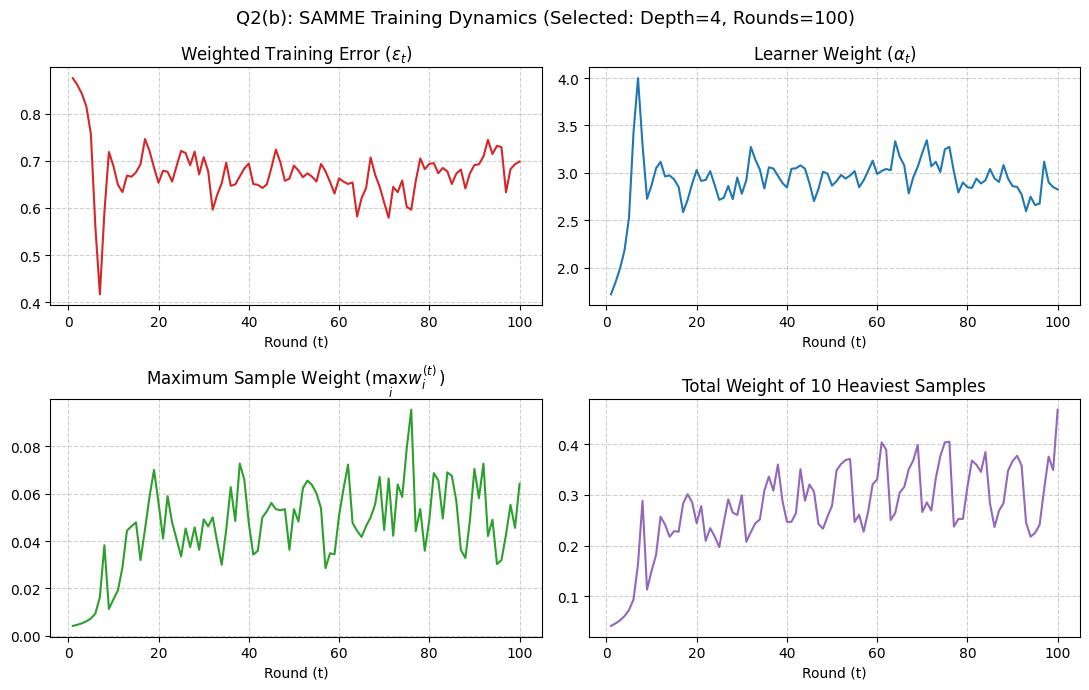

In [16]:
import time

# --- Q2(b): SAMME on Olivetti Faces across Depths {1, 2, 3, 4} and Rounds {10, 25, 50, 100} ---

boost_depths = [1, 2, 3, 4]
boost_rounds = [10, 25, 50, 100]
max_T = max(boost_rounds)  # 100
N_train = x_train.shape[0]
K = 40

def fit_samme_full(X_tr, y_tr, max_depth, n_rounds, K=40, base_seed=seed):
    """
    Fits SAMME for n_rounds using the exact samme_single_step function from Q2(a).
    Logs round-by-round diagnostics and sample weight histories.
    """
    rng_boost = np.random.default_rng(base_seed)
    N = X_tr.shape[0]
    w = np.ones(N, dtype=np.float64) / N
    
    trees = []
    alphas = []
    
    # Diagnostics per round
    err_history = []
    alpha_history = []
    max_w_history = []
    top10_w_history = []
    w_matrix_history = []  # Stores weight vector w^(t) at the start of round t
    
    for t in range(n_rounds):
        # Log weight stats at round t
        w_matrix_history.append(w.copy())
        max_w_history.append(float(np.max(w)))
        top10_w_history.append(float(np.sum(np.sort(w)[-10:])))
        
        tree_seed = int(rng_boost.integers(0, 2**31 - 1))
        tree, preds, err, alpha, w_next, is_valid = samme_single_step(
            X_tr, y_tr, w, max_depth=max_depth, K=K, tree_seed=tree_seed
        )
        
        if not is_valid:
            # Weak learner not better than random (1 - 1/K): perturb weights slightly or break if stuck
            if len(trees) == 0:
                trees.append(tree)
                alphas.append(1.0)
                err_history.append(err)
                alpha_history.append(1.0)
            break
            
        trees.append(tree)
        alphas.append(alpha)
        err_history.append(err)
        alpha_history.append(alpha)
        w = w_next
        
    return {
        "trees": trees,
        "alphas": np.array(alphas, dtype=np.float64),
        "err_history": err_history,
        "alpha_history": alpha_history,
        "max_w_history": max_w_history,
        "top10_w_history": top10_w_history,
        "w_matrix_history": np.array(w_matrix_history)
    }

def predict_samme(model_dict, X_eval, n_rounds=None, K=40):
    """
    Computes normalised weighted votes q_k(x) = S_k(x) / sum(alpha_t)
    using the first n_rounds learners.
    """
    trees = model_dict["trees"][:n_rounds]
    alphas = model_dict["alphas"][:n_rounds]
    n_samples = X_eval.shape[0]
    
    S = np.zeros((n_samples, K), dtype=np.float64)
    for tree, alpha in zip(trees, alphas):
        preds = tree.predict(X_eval)
        S[np.arange(n_samples), preds] += alpha
        
    q = S / np.sum(alphas)
    preds_final = np.argmax(q, axis=1)
    mean_conf = float(np.mean(np.max(q, axis=1)))
    return preds_final, mean_conf, q

results_q2b = []
trained_boosting_by_depth = {}

print("Training SAMME models for depths 1, 2, 3, 4 (up to 100 rounds each)...")
for d in boost_depths:
    t0 = time.time()
    model_d = fit_samme_full(x_train, y_train, max_depth=d, n_rounds=max_T, K=K, base_seed=seed)
    elapsed_100 = time.time() - t0
    trained_boosting_by_depth[d] = model_d
    print(f"  Depth {d}: completed {len(model_d['trees'])} rounds in {elapsed_100:.2f}s")
    
    for T in boost_rounds:
        tr_preds, _, _  = predict_samme(model_d, x_train, n_rounds=T, K=K)
        val_preds, _, _ = predict_samme(model_d, x_val,   n_rounds=T, K=K)
        te_preds, _, _  = predict_samme(model_d, x_test,  n_rounds=T, K=K)
        
        results_q2b.append({
            "depth": d,
            "rounds": T,
            "train_acc": round(np.mean(tr_preds == y_train), 4),
            "val_acc": round(np.mean(val_preds == y_val), 4),
            "test_acc": round(np.mean(te_preds == y_test), 4)
        })

df_q2b = pd.DataFrame(results_q2b)
print("\n=== Q2(b): SAMME Grid Search Results ===")
print(df_q2b.to_string(index=False))

# Automatically select best (depth, rounds) using clean validation accuracy only
best_row = df_q2b.sort_values(by=["val_acc", "rounds"], ascending=[False, True]).iloc[0]
BEST_BOOST_DEPTH  = int(best_row["depth"])
BEST_BOOST_ROUNDS = int(best_row["rounds"])
print(f"\nSelected Boosting Model -> depth = {BEST_BOOST_DEPTH}, rounds = {BEST_BOOST_ROUNDS} (Val Acc: {best_row['val_acc']:.4f})")

# --- Plot the 4 diagnostic curves for the selected model ---
sel_model = trained_boosting_by_depth[BEST_BOOST_DEPTH]
rounds_axis = np.arange(1, BEST_BOOST_ROUNDS + 1)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].plot(rounds_axis, sel_model["err_history"][:BEST_BOOST_ROUNDS], color="tab:red")
axes[0, 0].set_title("Weighted Training Error ($\epsilon_t$)")
axes[0, 0].set_xlabel("Round (t)")
axes[0, 0].grid(True, linestyle="--", alpha=0.6)

axes[0, 1].plot(rounds_axis, sel_model["alpha_history"][:BEST_BOOST_ROUNDS], color="tab:blue")
axes[0, 1].set_title("Learner Weight ($\\alpha_t$)")
axes[0, 1].set_xlabel("Round (t)")
axes[0, 1].grid(True, linestyle="--", alpha=0.6)

axes[1, 0].plot(rounds_axis, sel_model["max_w_history"][:BEST_BOOST_ROUNDS], color="tab:green")
axes[1, 0].set_title("Maximum Sample Weight ($\max_i w_i^{(t)}$)")
axes[1, 0].set_xlabel("Round (t)")
axes[1, 0].grid(True, linestyle="--", alpha=0.6)

axes[1, 1].plot(rounds_axis, sel_model["top10_w_history"][:BEST_BOOST_ROUNDS], color="tab:purple")
axes[1, 1].set_title("Total Weight of 10 Heaviest Samples")
axes[1, 1].set_xlabel("Round (t)")
axes[1, 1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle(f"Q2(b): SAMME Training Dynamics (Selected: Depth={BEST_BOOST_DEPTH}, Rounds={BEST_BOOST_ROUNDS})", fontsize=13)
plt.tight_layout()
plt.show()

=== Q2(c): Boosting vs Bagging (25, 50, 100 Learners) ===
        Method  Learners  train_acc  val_acc  test_acc  train_time_sec
       Bagging        25     1.0000   0.8000    0.8375           30.32
Boosting (d=4)        25     0.9042   0.4000    0.4375            9.07
       Bagging        50     1.0000   0.8750    0.8375           60.76
Boosting (d=4)        50     0.9375   0.4000    0.4500           17.90
       Bagging       100     1.0000   0.8875    0.8625          121.73
Boosting (d=4)       100     0.9958   0.5375    0.4625           35.68

=== Q2(c): Inspection of Heaviest Training Face ===
Training Sample Index : #199 (True Identity: Class 33)
Initial Weight (t=1)  : 0.0042
Peak Weight           : 0.0954 (reached at Round t=76)
Mean Weight (100 rds) : 0.0205
Times Correctly Classified by Individual Weak Learners: 13 / 100 rounds
Rounds where Weak Learner got it RIGHT (1-indexed): [  2  10  22  30  38  45  53  61  68  76  83  91 100]


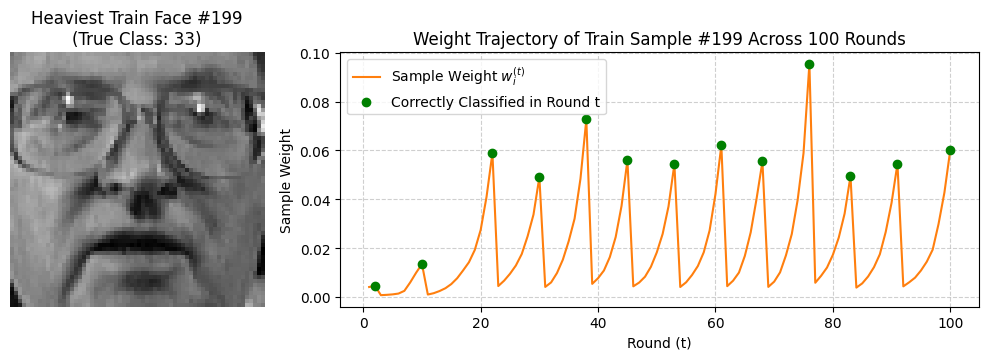


=== Q2(d): Clean vs Masked Evaluation (Single Tree, Bagging, Boosting) ===
                         Model  Clean Test Acc  Clean Mean Conf/Vote  Masked Test Acc  Masked Mean Conf/Vote
          Single Tree Baseline          0.4625                1.0000           0.4625                 1.0000
         Final Bagging (B=200)          0.8875                0.3957           0.8000                 0.2918
Selected Boosting (d=4, T=100)          0.4625                0.1208           0.5125                 0.1068

=== Q2(d): Face Where Bagging & Boosting Respond Differently to Masking ===
Test Sample #6 (True Class: 3)
  Bagging  -> Clean Pred: 3 (Vote: 83/200=0.415) | Masked Pred: 3 (Vote: 53/200=0.265)
  Boosting -> Clean Pred: 3 (q_win: 0.126) | Masked Pred: 20 (q_win: 0.092)


In [17]:
import time
import numpy as np

# --- Q2(c): Compare Boosting (depth=4) and Bagging using 25, 50, and 100 learners ---
learner_counts = [25, 50, 100]
results_q2c = []

for M in learner_counts:
    # 1. Time Bagging with M learners
    t0 = time.time()
    rng_b = np.random.default_rng(seed)
    bag_trees_M = []
    for b in range(M):
        boot_idx = rng_b.choice(N_train, size=N_train, replace=True)
        t_seed = int(rng_b.integers(0, 2**31 - 1))
        tree = DecisionTreeClassifier(max_depth=FROZEN_DEPTH, min_samples_leaf=FROZEN_MIN_LEAF, random_state=t_seed)
        tree.fit(x_train[boot_idx], y_train[boot_idx])
        bag_trees_M.append(tree)
    bag_time = time.time() - t0
    
    _, bag_tr_acc, _, _  = evaluate_bagging(bag_trees_M, x_train, y_train)
    _, bag_val_acc, _, _ = evaluate_bagging(bag_trees_M, x_val, y_val)
    _, bag_te_acc, _, _  = evaluate_bagging(bag_trees_M, x_test, y_test)
    
    results_q2c.append({
        "Method": "Bagging",
        "Learners": M,
        "train_acc": round(bag_tr_acc, 4),
        "val_acc": round(bag_val_acc, 4),
        "test_acc": round(bag_te_acc, 4),
        "train_time_sec": round(bag_time, 2)
    })
    
    # 2. Time Boosting (SAMME, depth=BEST_BOOST_DEPTH) with M learners
    t0 = time.time()
    boost_M = fit_samme_full(x_train, y_train, max_depth=BEST_BOOST_DEPTH, n_rounds=M, K=K, base_seed=seed)
    boost_time = time.time() - t0
    
    b_tr_preds, _, _  = predict_samme(boost_M, x_train, n_rounds=M, K=K)
    b_val_preds, _, _ = predict_samme(boost_M, x_val,   n_rounds=M, K=K)
    b_te_preds, _, _  = predict_samme(boost_M, x_test,  n_rounds=M, K=K)
    
    results_q2c.append({
        "Method": f"Boosting (d={BEST_BOOST_DEPTH})",
        "Learners": M,
        "train_acc": round(np.mean(b_tr_preds == y_train), 4),
        "val_acc": round(np.mean(b_val_preds == y_val), 4),
        "test_acc": round(np.mean(b_te_preds == y_test), 4),
        "train_time_sec": round(boost_time, 2)
    })

df_q2c = pd.DataFrame(results_q2c)
print("=== Q2(c): Boosting vs Bagging (25, 50, 100 Learners) ===")
print(df_q2c.to_string(index=False))

# --- Q2(c) Part 2: Inspect the Training Face with the Largest Boosting Weight ---
w_hist = sel_model["w_matrix_history"]  # shape (100, 240)
peak_round, hardest_sample_idx = np.unravel_index(np.argmax(w_hist), w_hist.shape)
true_hard_class = y_train[hardest_sample_idx]

# Check how each of the 100 weak learners predicted this specific training sample
hard_sample_x = x_train[hardest_sample_idx:hardest_sample_idx+1]
weak_preds_hard = np.array([t.predict(hard_sample_x)[0] for t in sel_model["trees"]])
was_correct = (weak_preds_hard == true_hard_class)

print(f"\n=== Q2(c): Inspection of Heaviest Training Face ===")
print(f"Training Sample Index : #{hardest_sample_idx} (True Identity: Class {true_hard_class})")
print(f"Initial Weight (t=1)  : {w_hist[0, hardest_sample_idx]:.4f}")
print(f"Peak Weight           : {w_hist[peak_round, hardest_sample_idx]:.4f} (reached at Round t={peak_round + 1})")
print(f"Mean Weight (100 rds) : {np.mean(w_hist[:, hardest_sample_idx]):.4f}")
print(f"Times Correctly Classified by Individual Weak Learners: {np.sum(was_correct)} / 100 rounds")
print(f"Rounds where Weak Learner got it RIGHT (1-indexed): {np.where(was_correct)[0] + 1}")

# Plot weight trajectory of this sample + show the face
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={'width_ratios': [1, 2.5]})
ax1.imshow(x_train[hardest_sample_idx].reshape(64, 64), cmap="gray")
ax1.set_title(f"Heaviest Train Face #{hardest_sample_idx}\n(True Class: {true_hard_class})")
ax1.axis("off")

ax2.plot(np.arange(1, 101), w_hist[:, hardest_sample_idx], color="tab:orange", label="Sample Weight $w_i^{(t)}$")
correct_rounds = np.where(was_correct)[0] + 1
ax2.scatter(correct_rounds, w_hist[was_correct, hardest_sample_idx], color="green", zorder=5, label="Correctly Classified in Round t")
ax2.set_title(f"Weight Trajectory of Train Sample #{hardest_sample_idx} Across 100 Rounds")
ax2.set_xlabel("Round (t)")
ax2.set_ylabel("Sample Weight")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()
plt.tight_layout()
plt.show()

# --- Q2(d): Clean vs Masked Test Set for Single Tree, Bagging (B=200), and Boosting (d=4, T=100) ---
bst_clean_preds, bst_clean_conf, bst_clean_q = predict_samme(sel_model, x_test, n_rounds=BEST_BOOST_ROUNDS, K=K)
bst_mask_preds,  bst_mask_conf,  bst_mask_q  = predict_samme(sel_model, x_test_masked, n_rounds=BEST_BOOST_ROUNDS, K=K)

bst_clean_acc = float(np.mean(bst_clean_preds == y_test))
bst_mask_acc  = float(np.mean(bst_mask_preds == y_test))

df_q2d = pd.DataFrame([
    {
        "Model": "Single Tree Baseline",
        "Clean Test Acc": round(st_clean_acc, 4),
        "Clean Mean Conf/Vote": round(st_clean_conf, 4),
        "Masked Test Acc": round(st_mask_acc, 4),
        "Masked Mean Conf/Vote": round(st_mask_conf, 4)
    },
    {
        "Model": f"Final Bagging (B={B_FINAL})",
        "Clean Test Acc": round(bag_clean_acc, 4),
        "Clean Mean Conf/Vote": round(bag_clean_conf, 4),
        "Masked Test Acc": round(bag_mask_acc, 4),
        "Masked Mean Conf/Vote": round(bag_mask_conf, 4)
    },
    {
        "Model": f"Selected Boosting (d={BEST_BOOST_DEPTH}, T={BEST_BOOST_ROUNDS})",
        "Clean Test Acc": round(bst_clean_acc, 4),
        "Clean Mean Conf/Vote": round(bst_clean_conf, 4),
        "Masked Test Acc": round(bst_mask_acc, 4),
        "Masked Mean Conf/Vote": round(bst_mask_conf, 4)
    }
])
print("\n=== Q2(d): Clean vs Masked Evaluation (Single Tree, Bagging, Boosting) ===")
print(df_q2d.to_string(index=False))

# Find a face where Bagging and Boosting respond differently to the masked region
# Case A: Both get it right on Clean, but on Masked Bagging stays right while Boosting fails (or vice versa)
diff_response_candidates = np.where(
    (bag_clean_preds == y_test) & (bst_clean_preds == y_test) &
    (bag_mask_preds != bst_mask_preds)
)[0]

if len(diff_response_candidates) == 0:
    # Fallback: any sample where one model's prediction changes upon masking while the other stays stable
    diff_response_candidates = np.where(
        (bag_clean_preds == bag_mask_preds) != (bst_clean_preds == bst_mask_preds)
    )[0]

face_idx = diff_response_candidates[0]
print(f"\n=== Q2(d): Face Where Bagging & Boosting Respond Differently to Masking ===")
print(f"Test Sample #{face_idx} (True Class: {y_test[face_idx]})")
print(f"  Bagging  -> Clean Pred: {bag_clean_preds[face_idx]} (Vote: {bag_clean_votes[face_idx, bag_clean_preds[face_idx]]}/{B_FINAL}={bag_clean_votes[face_idx, bag_clean_preds[face_idx]]/B_FINAL:.3f}) | "
      f"Masked Pred: {bag_mask_preds[face_idx]} (Vote: {bag_mask_votes[face_idx, bag_mask_preds[face_idx]]}/{B_FINAL}={bag_mask_votes[face_idx, bag_mask_preds[face_idx]]/B_FINAL:.3f})")
print(f"  Boosting -> Clean Pred: {bst_clean_preds[face_idx]} (q_win: {bst_clean_q[face_idx, bst_clean_preds[face_idx]]:.3f}) | "
      f"Masked Pred: {bst_mask_preds[face_idx]} (q_win: {bst_mask_q[face_idx, bst_mask_preds[face_idx]]:.3f})")

In [1]:
import time
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

# --- 1. Reload Saved Splits & Constants (After Kernel Restart) ---
roll_number = "M26CSE005"  # <-- Put your exact same roll number here!
seed = int("".join([ch for ch in roll_number if ch.isdigit()]))

saved_data = np.load("olivetti_splits.npz")
x_train = saved_data["x_train"]
y_train = saved_data["y_train"]
x_val   = saved_data["x_val"]
y_val   = saved_data["y_val"]
x_test  = saved_data["x_test"]
y_test  = saved_data["y_test"]
x_test_masked = saved_data["x_test_masked"]

# Frozen settings from Q1 and Q2
FROZEN_DEPTH = None
FROZEN_MIN_LEAF = 1
B_FINAL = 200
BEST_BOOST_DEPTH = 4
BEST_BOOST_ROUNDS = 100

# Recorded Clean & Masked Test Accuracies from your Q1(d) & Q2(d) outputs
st_clean_acc,  st_mask_acc  = 0.4625, 0.4625
bag_clean_acc, bag_mask_acc = 0.8875, 0.8000
bst_clean_acc, bst_mask_acc = 0.4625, 0.5125

# --- 2. SAMME Helper Functions (Needed for Q3 Boosting Refits) ---
def samme_single_step(X_data, y_data, w, max_depth, K, tree_seed):
    tree = DecisionTreeClassifier(max_depth=max_depth, random_state=tree_seed)
    tree.fit(X_data, y_data, sample_weight=w)
    preds = tree.predict(X_data)
    incorrect = (preds != y_data).astype(np.float64)
    err = float(np.dot(w, incorrect) / np.sum(w))
    max_allowed_err = 1.0 - (1.0 / K)
    if err >= max_allowed_err - 1e-12:
        return tree, preds, err, 0.0, w.copy(), False
    err_clipped = np.clip(err, 1e-12, max_allowed_err - 1e-12)
    alpha = float(np.log((1.0 - err_clipped) / err_clipped) + np.log(K - 1.0))
    w_unnorm = w * np.exp(alpha * incorrect)
    w_updated = w_unnorm / np.sum(w_unnorm)
    return tree, preds, err, alpha, w_updated, True

def fit_samme_full(X_tr, y_tr, max_depth, n_rounds, K=40, base_seed=seed):
    rng_boost = np.random.default_rng(base_seed)
    N = X_tr.shape[0]
    w = np.ones(N, dtype=np.float64) / N
    trees, alphas = [], []
    for t in range(n_rounds):
        tree_seed = int(rng_boost.integers(0, 2**31 - 1))
        tree, preds, err, alpha, w_next, is_valid = samme_single_step(
            X_tr, y_tr, w, max_depth=max_depth, K=K, tree_seed=tree_seed
        )
        if not is_valid:
            if len(trees) == 0:
                trees.append(tree)
                alphas.append(1.0)
            break
        trees.append(tree)
        alphas.append(alpha)
        w = w_next
    return {"trees": trees, "alphas": np.array(alphas, dtype=np.float64)}

def predict_samme(model_dict, X_eval, n_rounds=None, K=40):
    trees = model_dict["trees"][:n_rounds]
    alphas = model_dict["alphas"][:n_rounds]
    n_samples = X_eval.shape[0]
    S = np.zeros((n_samples, K), dtype=np.float64)
    for tree, alpha in zip(trees, alphas):
        preds = tree.predict(X_eval)
        S[np.arange(n_samples), preds] += alpha
    q = S / np.sum(alphas)
    preds_final = np.argmax(q, axis=1)
    mean_conf = float(np.mean(np.max(q, axis=1)))
    return preds_final, mean_conf, q

# --- 3. QUESTION 3: Empirical Bias^2 and Variance Across R = 30 Stratified Resamples ---
R = 30
N_test = x_test.shape[0]  # 80
K = 40

# One-hot encoded test targets e_i: shape (80, 40)
E_test = np.eye(K)[y_test]

# Generate 30 resampled training sets (sampling 6 with replacement WITHIN each identity)
rng_q3 = np.random.default_rng(seed)
resampled_indices_list = []

for r in range(R):
    r_indices = []
    for person_id in range(K):
        id_mask = np.where(y_train == person_id)[0]
        sampled_6 = rng_q3.choice(id_mask, size=6, replace=True)
        r_indices.extend(sampled_6)
    resampled_indices_list.append(np.array(r_indices))

def compute_bv_metrics(P_array, E_target, y_true):
    P_bar = np.mean(P_array, axis=0)  # shape (N_test, K)
    bias_sq = float(np.mean(np.sum((P_bar - E_target) ** 2, axis=-1)))
    variance = float(np.mean(np.sum((P_array - P_bar[None, :, :]) ** 2, axis=-1)))
    preds_r = np.argmax(P_array, axis=-1)
    accs_r = np.mean(preds_r == y_true[None, :], axis=1)
    return bias_sq, variance, float(np.mean(accs_r)), float(np.std(accs_r))

P_single_d4    = np.zeros((R, N_test, K), dtype=np.float64)
P_single_d16   = np.zeros((R, N_test, K), dtype=np.float64)
P_single_dNone = np.zeros((R, N_test, K), dtype=np.float64)

P_bag100_d4    = np.zeros((R, N_test, K), dtype=np.float64)
P_bag100_d16   = np.zeros((R, N_test, K), dtype=np.float64)
P_bag100_dNone = np.zeros((R, N_test, K), dtype=np.float64)
P_bag200_dNone = np.zeros((R, N_test, K), dtype=np.float64)

P_boost_sel    = np.zeros((R, N_test, K), dtype=np.float64)

print("Running 30 stratified resampling repetitions for Q3...")
t_start = time.time()

for r in range(R):
    idx_r = resampled_indices_list[r]
    X_r, y_r = x_train[idx_r], y_train[idx_r]
    r_seed = int(rng_q3.integers(0, 2**31 - 1))
    
    # A. Single Trees at depths 4, 16, None
    for d_val, P_store in [(4, P_single_d4), (16, P_single_d16), (None, P_single_dNone)]:
        st = DecisionTreeClassifier(max_depth=d_val, min_samples_leaf=FROZEN_MIN_LEAF, random_state=r_seed)
        st.fit(X_r, y_r)
        P_store[r] = st.predict_proba(x_test)
        
    # B. Bagging at depths 4 (B=100), 16 (B=100), and None (B=200, slicing first 100 too)
    for d_val, B_run in [(4, 100), (16, 100), (None, 200)]:
        rng_b = np.random.default_rng(r_seed)
        votes_100 = np.zeros((N_test, K), dtype=np.float64)
        votes_200 = np.zeros((N_test, K), dtype=np.float64)
        
        for b in range(B_run):
            boot_idx = rng_b.choice(len(X_r), size=len(X_r), replace=True)
            t_seed = int(rng_b.integers(0, 2**31 - 1))
            tree = DecisionTreeClassifier(max_depth=d_val, min_samples_leaf=FROZEN_MIN_LEAF, random_state=t_seed)
            tree.fit(X_r[boot_idx], y_r[boot_idx])
            preds_b = tree.predict(x_test)
            if b < 100:
                votes_100[np.arange(N_test), preds_b] += 1.0
            votes_200[np.arange(N_test), preds_b] += 1.0
            
        if d_val == 4:
            P_bag100_d4[r] = votes_100 / 100.0
        elif d_val == 16:
            P_bag100_d16[r] = votes_100 / 100.0
        else:
            P_bag100_dNone[r] = votes_100 / 100.0
            P_bag200_dNone[r] = votes_200 / 200.0
            
    # C. Selected Boosting Model (depth=4, rounds=100)
    boost_r = fit_samme_full(X_r, y_r, max_depth=BEST_BOOST_DEPTH, n_rounds=BEST_BOOST_ROUNDS, K=K, base_seed=r_seed)
    _, _, q_r = predict_samme(boost_r, x_test, n_rounds=BEST_BOOST_ROUNDS, K=K)
    P_boost_sel[r] = q_r
    
    if (r + 1) % 5 == 0 or r == 0:
        print(f"  Completed repetition {r + 1}/{R} ({time.time() - t_start:.1f}s elapsed)")

# --- Table for Q3(a) ---
q3a_models = [
    ("Selected Single Tree (d=None)", P_single_dNone),
    (f"Final Bagging (B={B_FINAL}, d=None)", P_bag200_dNone),
    (f"Selected Boosting (d={BEST_BOOST_DEPTH}, T={BEST_BOOST_ROUNDS})", P_boost_sel)
]

rows_q3a = []
bv_lookup = {}
for name, P_mat in q3a_models:
    b2, var, mean_acc, std_acc = compute_bv_metrics(P_mat, E_test, y_test)
    bv_lookup[name] = (b2, var, mean_acc, std_acc)
    rows_q3a.append({
        "Model": name,
        "Bias^2": round(b2, 4),
        "Variance": round(var, 4),
        "Bias^2 + Var": round(b2 + var, 4),
        "Mean Test Acc (30 refits)": round(mean_acc, 4),
        "Std Test Acc": round(std_acc, 4)
    })

df_q3a = pd.DataFrame(rows_q3a)
print("\n=== Q3(a): Empirical Bias^2, Variance, and Test Accuracy Across 30 Refits ===")
print(df_q3a.to_string(index=False))

# --- Table for Q3(b) & Q3(c) ---
depth_configs = [
    ("Shallow (depth=4)", P_single_d4, P_bag100_d4),
    ("Deeper (depth=16)", P_single_d16, P_bag100_d16),
    ("Selected/Unbounded (depth=None)", P_single_dNone, P_bag100_dNone)
]

rows_q3b = []
for d_label, P_st, P_bg in depth_configs:
    st_b2, st_var, st_acc, st_std = compute_bv_metrics(P_st, E_test, y_test)
    bg_b2, bg_var, bg_acc, bg_std = compute_bv_metrics(P_bg, E_test, y_test)
    
    rows_q3b.append({
        "Depth Setting": d_label,
        "Single Tree Bias^2": round(st_b2, 4),
        "Bagging(100) Bias^2": round(bg_b2, 4),
        "Single Tree Var": round(st_var, 4),
        "Bagging(100) Var": round(bg_var, 4),
        "Var Removed (%)": round(100.0 * (st_var - bg_var) / st_var, 2),
        "Single Tree Mean Acc": round(st_acc, 4),
        "Bagging(100) Mean Acc": round(bg_acc, 4),
        "Acc Gain (+)": round(bg_acc - st_acc, 4)
    })

df_q3b = pd.DataFrame(rows_q3b)
print("\n=== Q3(b) & Q3(c): Effect of Depth on Bias^2, Variance, and 100-Tree Bagging Gain ===")
print(df_q3b.to_string(index=False))

# --- Final Summary Table for Q3(d) ---
st_b2, st_var, _, _   = bv_lookup["Selected Single Tree (d=None)"]
bag_b2, bag_var, _, _ = bv_lookup[f"Final Bagging (B={B_FINAL}, d=None)"]
bst_b2, bst_var, _, _ = bv_lookup[f"Selected Boosting (d={BEST_BOOST_DEPTH}, T={BEST_BOOST_ROUNDS})"]

df_q3d = pd.DataFrame([
    {
        "Model": "Selected Single Tree (d=None)",
        "Clean Test Acc": round(st_clean_acc, 4),
        "Masked Test Acc": round(st_mask_acc, 4),
        "Bias^2": round(st_b2, 4),
        "Variance": round(st_var, 4)
    },
    {
        "Model": f"Final Bagging (B={B_FINAL})",
        "Clean Test Acc": round(bag_clean_acc, 4),
        "Masked Test Acc": round(bag_mask_acc, 4),
        "Bias^2": round(bag_b2, 4),
        "Variance": round(bag_var, 4)
    },
    {
        "Model": f"Selected Boosting (d={BEST_BOOST_DEPTH}, T={BEST_BOOST_ROUNDS})",
        "Clean Test Acc": round(bst_clean_acc, 4),
        "Masked Test Acc": round(bst_mask_acc, 4),
        "Bias^2": round(bst_b2, 4),
        "Variance": round(bst_var, 4)
    }
])
print("\n=== Q3(d): Final Master Comparison Table ===")
print(df_q3d.to_string(index=False))

Running 30 stratified resampling repetitions for Q3...
  Completed repetition 1/30 (367.3s elapsed)
  Completed repetition 5/30 (1798.0s elapsed)
  Completed repetition 10/30 (3555.5s elapsed)
  Completed repetition 15/30 (5355.4s elapsed)
  Completed repetition 20/30 (7127.7s elapsed)
  Completed repetition 25/30 (8914.9s elapsed)
  Completed repetition 30/30 (10693.0s elapsed)

=== Q3(a): Empirical Bias^2, Variance, and Test Accuracy Across 30 Refits ===
                         Model  Bias^2  Variance  Bias^2 + Var  Mean Test Acc (30 refits)  Std Test Acc
 Selected Single Tree (d=None)  0.3984    0.6491        1.0475                     0.4763        0.0525
 Final Bagging (B=200, d=None)  0.5111    0.0216        0.5328                     0.7967        0.0368
Selected Boosting (d=4, T=100)  0.8850    0.0173        0.9023                     0.3146        0.0698

=== Q3(b) & Q3(c): Effect of Depth on Bias^2, Variance, and 100-Tree Bagging Gain ===
                  Depth Setting  Sin